# Q1

### Q1-A

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier

In [2]:
roll_number = "P26CS0009"

seed = int("".join
           (char for char in roll_number if char.isdigit())
           )

In [3]:
print(f"Seed value: {seed}")

Seed value: 260009


In [4]:
folder = Path(f"ML_Assignment_2_{roll_number}")
(folder / "split").mkdir(parents=True, exist_ok=True)

In [5]:
print(f"folder: {folder}")

folder: ML_Assignment_2_P26CS0009


In [6]:
faces = fetch_olivetti_faces(
    data_home=str(folder / "data_cache"),
    shuffle=False
)

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to ML_Assignment_2_P26CS0009\data_cache


In [7]:
features = faces.data
labels = faces.target

In [8]:
print("Features:", features.shape)
print("Labels:", labels.shape)  
print("Number of people:", len(np.unique(labels)))

Features: (400, 4096)
Labels: (400,)
Number of people: 40


In [9]:
rng = np.random.default_rng(seed)

train_indices = []
validation_indices = []
test_indices = []

for person in np.unique(labels):

    person_indices = np.where(labels == person)[0]
    person_indices = rng.permutation(person_indices)

    train_indices.extend(person_indices[:6])
    validation_indices.extend(person_indices[6:8])
    test_indices.extend(person_indices[8:10])

In [10]:
train_indices = np.array(train_indices)
validation_indices = np.array(validation_indices)
test_indices = np.array(test_indices)

split_file = folder / "split" / "olivetti_split.npz"

np.savez_compressed(
    split_file,
    train_indices=train_indices,
    validation_indices=validation_indices,
    test_indices=test_indices
)

print("Split indices saved.")

Split indices saved.


In [11]:
training_features = features[train_indices]
training_labels = labels[train_indices]

validation_features = features[validation_indices]
validation_labels = labels[validation_indices]

test_features = features[test_indices]
test_labels = labels[test_indices]

In [12]:
print("Training:", len(training_labels))
print("Validation:", len(validation_labels))
print("Testing:", len(test_labels))

Training: 240
Validation: 80
Testing: 80


In [13]:
tree_depths = [2, 4, 8, 16, None]
leaf_sizes = [1, 2, 4]

tree_models = []
tree_results = []

In [14]:
for depth in tree_depths:

    for leaf_size in leaf_sizes:

        tree = DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            min_samples_leaf=leaf_size,
            random_state=seed
        )

        tree.fit(training_features, training_labels)

        tree_models.append(tree)

In [15]:
for tree in tree_models:

    training_accuracy = tree.score(
        training_features, training_labels
    )

    validation_accuracy = tree.score(
        validation_features, validation_labels
    )

    tree_results.append({
        "max_depth": str(tree.max_depth),
        "min_samples_leaf": tree.min_samples_leaf,
        "train_accuracy": training_accuracy,
        "validation_accuracy": validation_accuracy,
        "depth_order": tree_depths.index(tree.max_depth)
    })

In [16]:
for index, tree in enumerate(tree_models):

    leaf_ids = tree.apply(training_features)

    unique_leaves, leaf_counts = np.unique(
        leaf_ids, return_counts=True
    )

    tree_results[index]["leaves"] = len(unique_leaves)

    tree_results[index]["mean_leaf_size"] = leaf_counts.mean()

    tree_results[index]["singleton_fraction"] = np.mean(
        leaf_counts == 1
    )

In [17]:
q1a = pd.DataFrame(tree_results)

display(q1a.drop(columns="depth_order").round(4))

,max_depth,min_samples_leaf,train_accuracy,validation_accuracy,leaves,mean_leaf_size,singleton_fraction
0,2,1,0.0750,0.0500,3,80.0000,0.0000
1,2,2,0.0750,0.0500,3,80.0000,0.0000
2,2,4,0.0750,0.0500,3,80.0000,0.0000
3,4,1,0.1250,0.1000,5,48.0000,0.0000
4,4,2,0.1250,0.1000,5,48.0000,0.0000
5,4,4,0.1250,0.1000,5,48.0000,0.0000
6,8,1,0.2250,0.2000,9,26.6667,0.0000
7,8,2,0.2250,0.2000,9,26.6667,0.0000
8,8,4,0.2250,0.2000,9,26.6667,0.0000
9,16,1,0.4333,0.3625,19,12.6316,0.1053


In [18]:
sorted_results = q1a.sort_values(
    ["validation_accuracy", "depth_order", "min_samples_leaf"],
    ascending=[False, True, False]
)

best_index = sorted_results.index[0]

best_tree = tree_models[best_index]

In [19]:
print("Best depth:", best_tree.max_depth)

Best depth: None


In [20]:
print("Best minimum leaf size:", best_tree.min_samples_leaf)

Best minimum leaf size: 4


In [21]:
print(
    "Best validation accuracy:",
    best_tree.score(validation_features, validation_labels)
)

Best validation accuracy: 0.675


In [22]:
q1a["test_accuracy"] = [
    tree.score(test_features, test_labels)
    for tree in tree_models
]

In [23]:
display(q1a.drop(columns="depth_order").round(4))

,max_depth,min_samples_leaf,train_accuracy,validation_accuracy,leaves,mean_leaf_size,singleton_fraction,test_accuracy
0,2,1,0.0750,0.0500,3,80.0000,0.0000,0.0750
1,2,2,0.0750,0.0500,3,80.0000,0.0000,0.0750
2,2,4,0.0750,0.0500,3,80.0000,0.0000,0.0750
3,4,1,0.1250,0.1000,5,48.0000,0.0000,0.1125
4,4,2,0.1250,0.1000,5,48.0000,0.0000,0.1125
5,4,4,0.1250,0.1000,5,48.0000,0.0000,0.1125
6,8,1,0.2250,0.2000,9,26.6667,0.0000,0.1875
7,8,2,0.2250,0.2000,9,26.6667,0.0000,0.1875
8,8,4,0.2250,0.2000,9,26.6667,0.0000,0.1875
9,16,1,0.4333,0.3625,19,12.6316,0.1053,0.3375


In [24]:
tree_params = {
    "criterion": best_tree.criterion,
    "max_depth": best_tree.max_depth,
    "min_samples_leaf": best_tree.min_samples_leaf
}

In [25]:
print("Frozen tree settings:", tree_params)

Frozen tree settings: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 4}


### Q1-B

In [26]:
from time import perf_counter

In [27]:
classes = np.unique(labels)

In [28]:
B_values = [1, 5, 10, 25, 50, 100, 200]

In [29]:
def tree_predictions(trees, features):

    predictions = []

    for tree in trees:
        prediction = tree.predict(features)
        predictions.append(prediction)

    return np.array(predictions)

In [30]:
def vote_counts(predictions, eligible=None):

    if eligible is None:
        eligible = np.ones_like(predictions, dtype=bool)

    counts = np.zeros(
        (predictions.shape[1], len(classes)),
        dtype=int
    )

    for index, person in enumerate(classes):

        votes = (predictions == person) & eligible
        counts[:, index] = votes.sum(axis=0)

    return counts

In [31]:
def labels_from_votes(votes):

    best_indices = np.argmax(votes, axis=1)

    predicted_labels = classes[best_indices]

    return predicted_labels

In [32]:
def fit_bagging(features, targets, parameters, B, seed):

    rng = np.random.default_rng(seed)
    number_of_samples = len(targets)

    trees = []
    samples = []
    times = []

    start_time = perf_counter()

    for i in range(B):

        indices = rng.integers(
            0, number_of_samples, size=number_of_samples
        )

        tree_seed = int(
            rng.integers(0, np.iinfo(np.int32).max)
        )

        tree = DecisionTreeClassifier(
            **parameters,
            random_state=tree_seed
        )

        tree.fit(features[indices], targets[indices])

        trees.append(tree)
        samples.append(indices)
        times.append(perf_counter() - start_time)
        
        if (i + 1) % 25 == 0:
            print(f"Trained {i + 1}/{B} trees", flush=True)

    return trees, np.array(samples), np.array(times)

In [33]:
seed_generator = np.random.default_rng(
    np.random.SeedSequence([seed, 2, 0])
)

In [34]:
bagging_seed = int(
    seed_generator.integers(0, np.iinfo(np.int32).max)
)

In [35]:
bag_trees, bootstrap_indices, bag_times = fit_bagging(
    training_features,
    training_labels,
    tree_params,
    max(B_values),
    bagging_seed
)


Trained 25/200 trees
Trained 50/200 trees
Trained 75/200 trees
Trained 100/200 trees
Trained 125/200 trees
Trained 150/200 trees
Trained 175/200 trees
Trained 200/200 trees


In [36]:
print("Total trees trained:", len(bag_trees))

Total trees trained: 200


In [37]:
train_predictions = tree_predictions(
    bag_trees, training_features
)

In [38]:
val_predictions = tree_predictions(
    bag_trees, validation_features
)

In [39]:
val_accuracy = {}

for B in B_values:

    predictions = val_predictions[:B]

    votes = vote_counts(predictions)
    predicted_labels = labels_from_votes(votes)

    accuracy = np.mean(predicted_labels == validation_labels)

    val_accuracy[B] = accuracy

In [40]:
for B in B_values:

    print(f"When B = {B}, Validation Accuracy = {val_accuracy[B]}")

When B = 1, Validation Accuracy = 0.4125
When B = 5, Validation Accuracy = 0.525
When B = 10, Validation Accuracy = 0.7125
When B = 25, Validation Accuracy = 0.8375
When B = 50, Validation Accuracy = 0.8625
When B = 100, Validation Accuracy = 0.8875
When B = 200, Validation Accuracy = 0.8875


In [41]:
best_B = B_values[0]

for B in B_values:

    if val_accuracy[B] > val_accuracy[best_B]:
        best_B = B

In [42]:
print("Best B and Best Validation Accuracy:", best_B, "and", val_accuracy[best_B])

Best B and Best Validation Accuracy: 100 and 0.8875


In [43]:
final_bagging = bag_trees[:best_B]

print("Trees in final ensemble:", len(final_bagging))

Trees in final ensemble: 100


In [44]:
test_predictions = tree_predictions(
    bag_trees, test_features
)

In [45]:
distinct = []

for indices in bootstrap_indices:

    unique_samples = np.unique(indices)

    distinct.append(len(unique_samples))

distinct = np.array(distinct)

In [46]:
number_of_samples = len(training_labels)

expected_distinct = number_of_samples * (
    1 - (1 - 1 / number_of_samples) ** number_of_samples
)

In [47]:
print("Expected distinct samples:", round(expected_distinct, 3))

Expected distinct samples: 151.893


In [48]:
bagging_results = []

for B in B_values:

    train_votes = vote_counts(train_predictions[:B])
    train_labels_predicted = labels_from_votes(train_votes)

    test_votes = vote_counts(test_predictions[:B])
    test_labels_predicted = labels_from_votes(test_votes)

    train_accuracy = np.mean(
        train_labels_predicted == training_labels
    )

    test_accuracy = np.mean(
        test_labels_predicted == test_labels
    )

    bagging_results.append({
        "B": B,
        "train_accuracy": train_accuracy,
        "validation_accuracy": val_accuracy[B],
        "test_accuracy": test_accuracy
    })

In [49]:
for index, B in enumerate(B_values):

    bagging_results[index]["mean_distinct"] = distinct[:B].mean()

    bagging_results[index]["expected_distinct"] = expected_distinct

    bagging_results[index]["training_seconds"] = bag_times[B - 1]

In [50]:
q1b = pd.DataFrame(bagging_results)

display(q1b.round(4))

,B,train_accuracy,validation_accuracy,test_accuracy,mean_distinct,expected_distinct,training_seconds
0,1,0.6750,0.4125,0.3750,154.00,151.8932,1.3474
1,5,0.9208,0.5250,0.5750,148.40,151.8932,6.8513
2,10,0.9708,0.7125,0.6750,149.80,151.8932,12.5805
3,25,1.0000,0.8375,0.7875,150.72,151.8932,30.3212
4,50,1.0000,0.8625,0.8625,151.56,151.8932,65.3561
5,100,1.0000,0.8875,0.9000,151.60,151.8932,123.2512
6,200,1.0000,0.8875,0.9250,151.70,151.8932,232.5178


In [51]:
print("Best B:", best_B)
print("Number of training samples:", number_of_samples)
print("Expected distinct samples:", round(expected_distinct, 3))
print("Total trees trained:", len(bag_trees))

Best B: 100
Number of training samples: 240
Expected distinct samples: 151.893
Total trees trained: 200


### Q1-C

In [52]:
import matplotlib.pyplot as plt

In [53]:
def disagreement(votes):

    B = int(votes[0].sum())

    if B < 2:
        return np.nan

    agreeing_pairs = (votes * (votes - 1)).sum(axis=1)

    disagreement_values = 1 - agreeing_pairs / (B * (B - 1))

    return np.mean(disagreement_values)

In [54]:
def mean_margin(votes):

    sorted_votes = np.sort(votes, axis=1)

    top_two = sorted_votes[:, -2:]

    margins = (
        (top_two[:, 1] - top_two[:, 0]) / votes.sum(axis=1)
    )

    return np.mean(margins)

In [55]:
number_of_samples = len(training_labels)

in_bag = np.zeros(
    (len(bag_trees), number_of_samples),
    dtype=bool
)

In [56]:
for tree_index, indices in enumerate(bootstrap_indices):

    in_bag[tree_index, indices] = True

In [57]:
oob_results = []

for B in B_values:

    oob_votes = vote_counts(
        train_predictions[:B],
        eligible=~in_bag[:B]
    )

    covered = oob_votes.sum(axis=1) > 0

    if covered.any():

        predicted_labels = labels_from_votes(
            oob_votes[covered]
        )

        oob_accuracy = np.mean(
            predicted_labels == training_labels[covered]
        )

    else:
        oob_accuracy = np.nan

    oob_coverage = covered.mean()

    oob_results.append({
        "B": B,
        "oob_accuracy": oob_accuracy,
        "oob_coverage": oob_coverage
    })

In [58]:
for index, B in enumerate(B_values):

    validation_votes = vote_counts(val_predictions[:B])

    oob_results[index]["disagreement"] = disagreement(
        validation_votes
    )

    oob_results[index]["mean_margin"] = mean_margin(
        validation_votes
    )

    oob_results[index]["validation_accuracy"] = val_accuracy[B]

In [59]:
q1c = pd.DataFrame(oob_results)

print("OOB results:")
display(q1c.round(4))

OOB results:


,B,oob_accuracy,oob_coverage,disagreement,mean_margin,validation_accuracy
0,1,0.3023,0.3583,NaN,1.0000,0.4125
1,5,0.3148,0.9000,0.7625,0.2775,0.5250
2,10,0.4142,0.9958,0.7833,0.2612,0.7125
3,25,0.5708,1.0000,0.7978,0.2525,0.8375
4,50,0.6750,1.0000,0.7923,0.2708,0.8625
5,100,0.7375,1.0000,0.8013,0.2658,0.8875
6,200,0.7500,1.0000,0.8004,0.2739,0.8875


In [60]:
print("Validation-selected B:", best_B)

Validation-selected B: 100


In [61]:
best_oob_index = q1c["oob_accuracy"].idxmax()

best_oob_B = int(q1c.loc[best_oob_index, "B"])

print("B with highest OOB accuracy:", best_oob_B)

B with highest OOB accuracy: 200


In [62]:
best_margin_index = q1c["mean_margin"].idxmax()

best_margin_B = int(q1c.loc[best_margin_index, "B"])

print("B with highest mean margin:", best_margin_B)

B with highest mean margin: 1


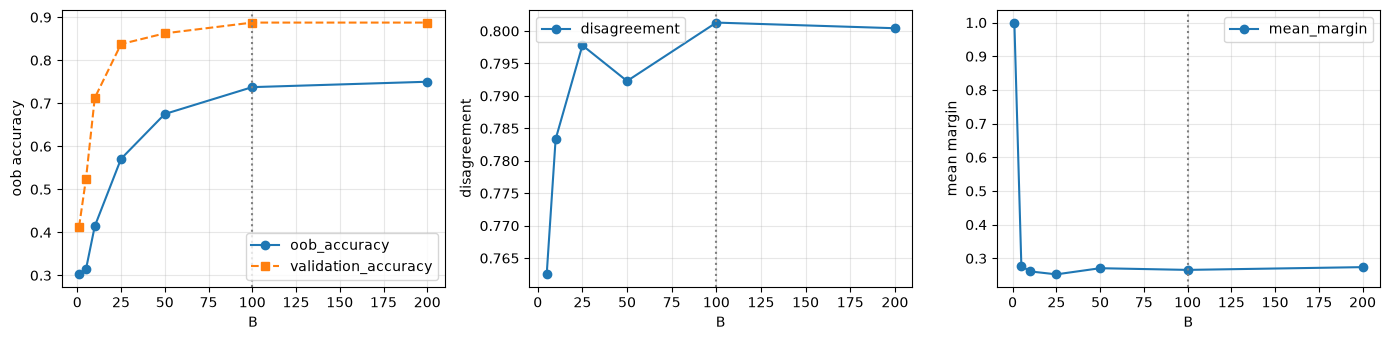

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

metrics = ["oob_accuracy", "disagreement", "mean_margin"]

for ax, metric in zip(axes, metrics):

    ax.plot(q1c["B"], q1c[metric], "o-", label=metric)

    if metric == "oob_accuracy":
        ax.plot(
            q1c["B"],
            q1c["validation_accuracy"],
            "s--",
            label="validation_accuracy"
        )

    ax.axvline(best_B, color="gray", linestyle=":")

    ax.set_xlabel("B")
    ax.set_ylabel(metric.replace("_", " "))

    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Q1-D

In [64]:
images = faces.images

test_images = images[test_indices].copy()

In [65]:
masked_images = test_images.copy()

mask_size = 16
height, width = masked_images.shape[1:]

row_start = (height - mask_size) // 2
column_start = (width - mask_size) // 2

row_end = row_start + mask_size
column_end = column_start + mask_size

masked_images[
    :,
    row_start:row_end,
    column_start:column_end
] = 0

In [66]:
masked_features = masked_images.reshape(
    len(test_indices), -1
)

In [67]:
print("Masked features shape:", masked_features.shape)

Masked features shape: (80, 4096)


In [68]:
clean_counts = vote_counts(
    test_predictions[:best_B]
)

In [69]:
masked_counts = vote_counts(
    tree_predictions(final_bagging, masked_features)
)

In [70]:
tree_clean = best_tree.predict_proba(test_features)
tree_masked = best_tree.predict_proba(masked_features)

In [71]:
bag_clean = clean_counts / best_B
bag_masked = masked_counts / best_B

In [72]:
print(
    "Class order matches:",
    np.array_equal(best_tree.classes_, classes)
)

Class order matches: True


In [73]:
results = []

for model, clean, masked in [
    ("Single tree", tree_clean, tree_masked),
    ("Bagging", bag_clean, bag_masked)
]:

    clean_predictions = labels_from_votes(clean)
    masked_predictions = labels_from_votes(masked)

    clean_accuracy = np.mean(
        clean_predictions == test_labels
    )

    masked_accuracy = np.mean(
        masked_predictions == test_labels
    )

    clean_confidence = clean.max(axis=1).mean()
    masked_confidence = masked.max(axis=1).mean()

    results.append({
        "model": model,
        "clean_accuracy": clean_accuracy,
        "masked_accuracy": masked_accuracy,
        "clean_confidence": clean_confidence,
        "masked_confidence": masked_confidence
    })

In [74]:
q1d = pd.DataFrame(results)
display(q1d.round(4))

,model,clean_accuracy,masked_accuracy,clean_confidence,masked_confidence
0,Single tree,0.65,0.4125,0.9714,0.9929
1,Bagging,0.90,0.5625,0.3775,0.2399


In [75]:
tree_labels = labels_from_votes(tree_clean)
bag_labels = labels_from_votes(bag_clean)

In [76]:
corrected = np.flatnonzero(
    (tree_labels != test_labels) &
    (bag_labels == test_labels)
)

In [77]:
both_wrong = np.flatnonzero(
    (tree_labels != test_labels) &
    (bag_labels != test_labels)
)


In [78]:
print("Bagging corrects tree:", len(corrected))
print("Both models wrong:", len(both_wrong))

Bagging corrects tree: 21
Both models wrong: 7


In [79]:
cases = []

for name, positions in [
    ("Bagging corrects tree", corrected),
    ("Both wrong", both_wrong)
]:

    print(
        f"{name}: {len(positions)} available and "
        f"showing {min(2, len(positions))}."
    )

    for position in positions[:2]:
        cases.append((name, position))

Bagging corrects tree: 21 available and showing 2.
Both wrong: 7 available and showing 2.


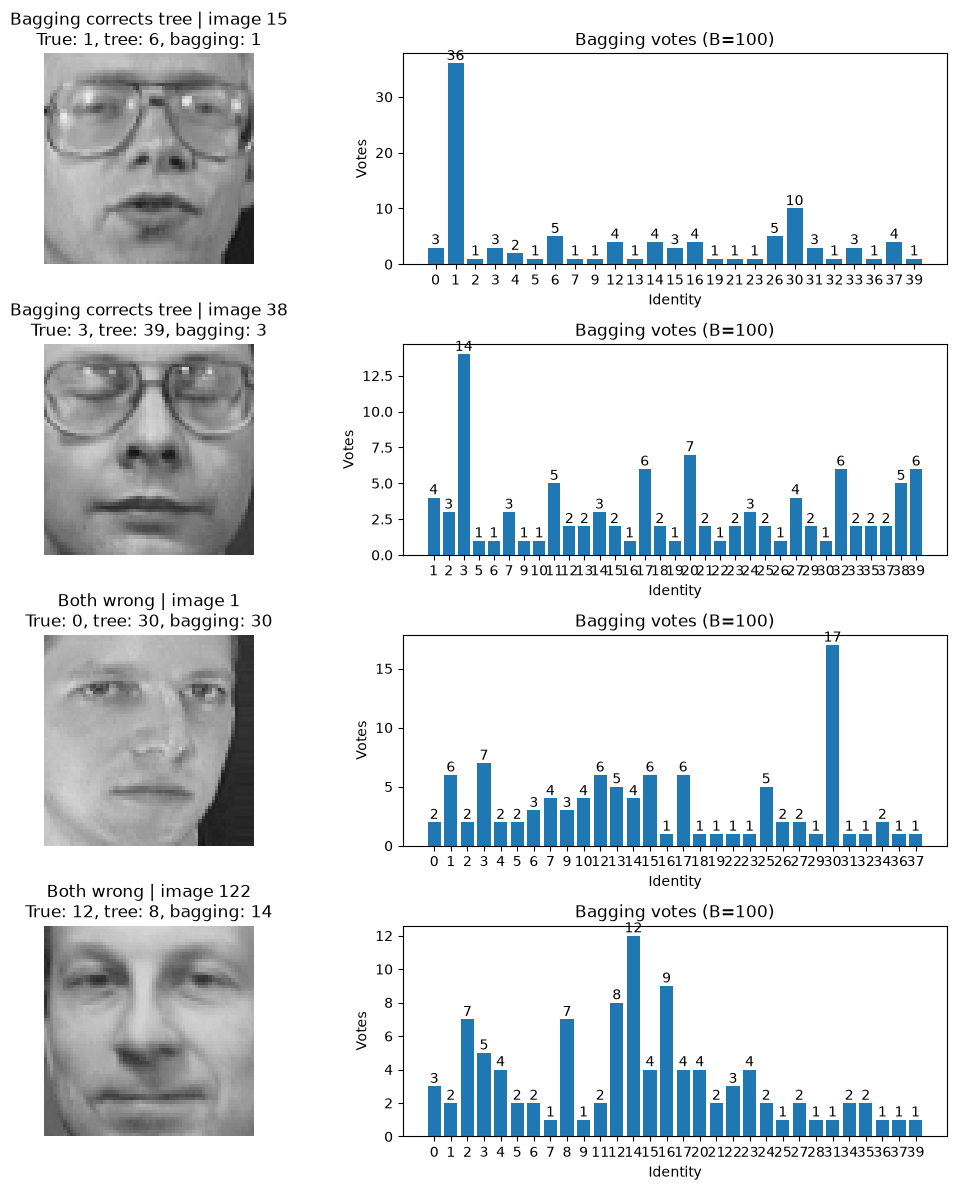

In [80]:
if cases:

    fig, axes = plt.subplots(
        len(cases),
        2,
        figsize=(11, 3 * len(cases)),
        squeeze=False
    )

    for row, (name, position) in enumerate(cases):

        axes[row, 0].imshow(
            images[test_indices[position]],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, 0].set_title(
            f"{name} | image {test_indices[position]}\n"
            f"True: {test_labels[position]}, "
            f"tree: {tree_labels[position]}, "
            f"bagging: {bag_labels[position]}"
        )

        axes[row, 0].axis("off")

        present = np.flatnonzero(
            clean_counts[position]
        )

        bars = axes[row, 1].bar(
            classes[present].astype(str),
            clean_counts[position, present]
        )

        axes[row, 1].bar_label(bars, fmt="%d")

        axes[row, 1].set(
            xlabel="Identity",
            ylabel="Votes",
            title=f"Bagging votes (B={best_B})"
        )

    plt.tight_layout()
    plt.show()

else:
    print("No examples available to display.")

# Q2

### Q2-A

In [81]:
def get_seed(stream, repetition=0):

    rng = np.random.default_rng(
        np.random.SeedSequence([seed, stream, repetition])
    )

    return int(rng.integers(0, np.iinfo(np.int32).max))

In [82]:
def samme_update(weights, y, pred, K):

    wrong = pred != y

    error = float(np.sum(weights * wrong))

    if error >= 1 - 1 / K - 1e-12:
        return error, None, weights.copy()

    safe_error = max(error, 1e-15)

    alpha = np.log((1 - safe_error) / safe_error) + np.log(K - 1)

    new_weights = weights * np.exp(alpha * wrong)

    new_weights /= new_weights.sum()

    return error, alpha, new_weights

In [83]:
toy_X = np.array([
    [20],
    [30],
    [50],
    [60],
    [80],
    [90]
])

toy_y = np.array([0, 0, 1, 1, 2, 2])

In [84]:
weights = np.full(
    len(toy_y),
    1 / len(toy_y)
)

print("Initial weights:", weights)

Initial weights: [0.16666667 0.16666667 0.16666667 0.16666667 0.16666667 0.16666667]


In [85]:
model = DecisionTreeClassifier(
    max_depth=1,
    random_state=get_seed(3)
)

In [86]:
model.fit(
    toy_X,
    toy_y,
    sample_weight=weights
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",4006678
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [87]:
pred = model.predict(toy_X)

print("True classes:", toy_y)
print("Predicted classes:", pred)

True classes: [0 0 1 1 2 2]
Predicted classes: [0 0 1 1 1 1]


In [88]:
error, alpha, new_weights = samme_update(
    weights,
    toy_y,
    pred,
    K=3
)

In [89]:
toy_results = pd.DataFrame({
    "score": toy_X.ravel(),
    "true_class": toy_y,
    "predicted_class": pred,
    "wrong": pred != toy_y,
    "initial_weight": weights,
    "updated_weight": new_weights
})

In [90]:
display(toy_results.round(6))

,score,true_class,predicted_class,wrong,initial_weight,updated_weight
0,20,0,0,False,0.166667,0.083333
1,30,0,0,False,0.166667,0.083333
2,50,1,1,False,0.166667,0.083333
3,60,1,1,False,0.166667,0.083333
4,80,2,1,True,0.166667,0.333333
5,90,2,1,True,0.166667,0.333333


In [91]:
print("Weighted error:", error)

print("Alpha:", alpha)

Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908


In [92]:
print("Sum of updated weights:", new_weights.sum())

Sum of updated weights: 1.0


### Q2-B

In [93]:
from time import perf_counter

In [94]:
def fit_samme(X, y, depth, T, random_seed):

    rng = np.random.default_rng(random_seed)
    labels = np.unique(y)

    weights = np.full(len(y), 1 / len(y))

    trees = []
    alphas = []
    predictions = []
    history = []
    times = []

    weight_history = [weights.copy()]

    reason = "Completed requested rounds"
    start = perf_counter()

    for t in range(T):

        model = DecisionTreeClassifier(
            criterion="gini",
            max_depth=depth,
            min_samples_leaf=1,
            random_state=int(
                rng.integers(0, np.iinfo(np.int32).max)
            )
        )

        model.fit(X, y, sample_weight=weights)

        pred = model.predict(X)

        error, alpha, new_weights = samme_update(
            weights, y, pred, len(labels)
        )

        if alpha is None:
            reason = (
                f"Rejected round {t + 1}: error {error:.6f} "
                "is not better than random"
            )
            break

        trees.append(model)
        alphas.append(alpha)
        predictions.append(pred)

        weights = new_weights
        weight_history.append(weights.copy())

        history.append({
            "round": t + 1,
            "weighted_error": error,
            "alpha": alpha,
            "max_weight": weights.max(),
            "top10_weight": np.sort(weights)[-10:].sum()
        })

        times.append(perf_counter() - start)

        if error == 0:
            reason = "Perfect learner accepted with finite alpha; stopped"
            break

    if not trees:
        raise ValueError(reason)

    return {
        "trees": trees,
        "alphas": np.array(alphas),
        "classes": labels,
        "predictions": np.array(predictions),
        "weights": np.array(weight_history),
        "history": pd.DataFrame(history),
        "times": np.array(times),
        "reason": reason
    }

In [95]:
def samme_vectors(model, X, T=None):

    if T is None:
        T = len(model["trees"])
    else:
        T = min(T, len(model["trees"]))

    votes = np.zeros(
        (len(X), len(model["classes"]))
    )

    for tree, alpha in zip(
        model["trees"][:T],
        model["alphas"][:T]
    ):

        pred = tree.predict(X)

        columns = np.searchsorted(
            model["classes"], pred
        )

        votes[np.arange(len(X)), columns] += alpha

    return votes / model["alphas"][:T].sum()

In [96]:
boost_models = {}
results = []

In [97]:
for depth in [1, 2, 3, 4]:

    model = fit_samme(
        training_features,
        training_labels,
        depth,
        100,
        get_seed(10 + depth)
    )

    boost_models[depth] = model

    print(
        f"Depth {depth}: {len(model['trees'])} accepted rounds. "
        f"{model['reason']}"
    )

Depth 1: 100 accepted rounds. Completed requested rounds
Depth 2: 100 accepted rounds. Completed requested rounds
Depth 3: 100 accepted rounds. Completed requested rounds
Depth 4: 100 accepted rounds. Completed requested rounds


In [98]:
for depth in [1, 2, 3, 4]:

    model = boost_models[depth]

    for T in [10, 25, 50, 100]:

        votes = samme_vectors(
            model,
            validation_features,
            T
        )

        predicted_labels = labels_from_votes(votes)

        validation_accuracy = np.mean(
            predicted_labels == validation_labels
        )

        results.append({
            "depth": depth,
            "rounds": T,
            "actual_rounds": min(T, len(model["trees"])),
            "validation_accuracy": validation_accuracy
        })

In [99]:
q2b = pd.DataFrame(results)

display(q2b.round(4))

,depth,rounds,actual_rounds,validation_accuracy
0,1,10,10,0.0375
1,1,25,25,0.0500
2,1,50,50,0.1250
3,1,100,100,0.0625
4,2,10,10,0.0750
5,2,25,25,0.1000
6,2,50,50,0.1250
7,2,100,100,0.2000
8,3,10,10,0.1125
9,3,25,25,0.2875


In [100]:
sorted_results = q2b.sort_values(
    ["validation_accuracy", "rounds", "depth"],
    ascending=[False, True, True]
)

best = sorted_results.iloc[0]

best_depth = int(best["depth"])
best_T = int(best["rounds"])

In [101]:
boost_bank = boost_models[best_depth]

used_T = min(
    best_T,
    len(boost_bank["trees"])
)

In [102]:
best_boosting = boost_bank.copy()

In [103]:
for key in ["trees", "alphas", "predictions", "times"]:

    best_boosting[key] = boost_bank[key][:used_T]

In [104]:
best_boosting["weights"] = boost_bank["weights"][:used_T + 1]

best_boosting["history"] = (
    boost_bank["history"].iloc[:used_T].copy()
)

In [105]:
if used_T < len(boost_bank["trees"]):

    best_boosting["reason"] = "Validation-selected prefix"

In [106]:
print("Selected depth:", best_depth)
print("Requested rounds:", best_T)
print("Actual rounds:", used_T)

Selected depth: 4
Requested rounds: 100
Actual rounds: 100


In [107]:
history = best_boosting["history"]

display(history.round(4))

,round,weighted_error,alpha,max_weight,top10_weight
0,1,0.8750,1.7177,0.0046,0.0464
1,2,0.8607,1.8423,0.0053,0.0526
2,3,0.8422,1.9887,0.0061,0.0609
3,4,0.7991,2.2830,0.0074,0.0743
4,5,0.7265,2.6868,0.0100,0.0997
...,...,...,...,...,...
95,96,0.6652,2.9772,0.0581,0.3954
96,97,0.6821,2.9003,0.0693,0.3930
97,98,0.6633,2.9854,0.0571,0.3074
98,99,0.6305,3.1292,0.0462,0.2163


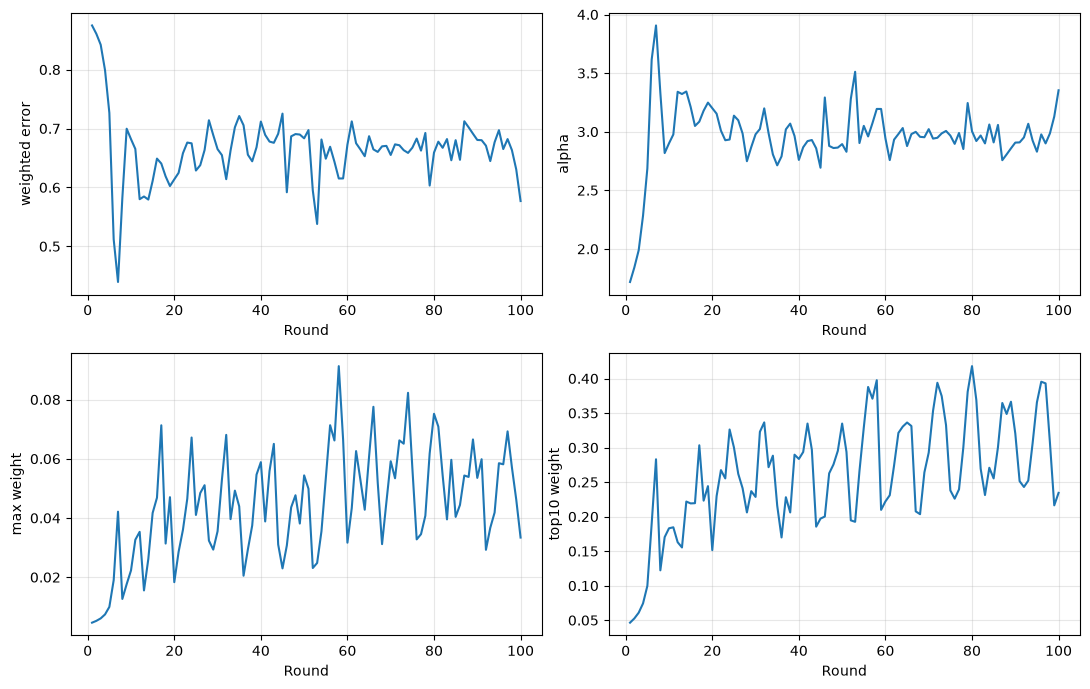

In [108]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(11, 7)
)

metrics = [
    "weighted_error",
    "alpha",
    "max_weight",
    "top10_weight"
]

for ax, metric in zip(axes.flat, metrics):

    ax.plot(
        history["round"],
        history[metric]
    )

    ax.set(
        xlabel="Round",
        ylabel=metric.replace("_", " ")
    )

    ax.grid(alpha=0.3)

plt.tight_layout()
(folder / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(folder / "figures" / "q2b_samme_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

### Q2-C

In [109]:
results = []

In [110]:
for T in [25, 50, 100]:

    bag_vectors = [
        vote_counts(predictions[:T]) / T
        for predictions in [
            train_predictions,
            val_predictions,
            test_predictions
        ]
    ]

    boost_vectors = [
        samme_vectors(boost_bank, features, T)
        for features in [
            training_features,
            validation_features,
            test_features
        ]
    ]

    actual_T = min(T, len(boost_bank["trees"]))

    for name, vectors, count, seconds in [
        ("Bagging", bag_vectors, T, bag_times[T - 1]),
        ("Boosting", boost_vectors, actual_T,
         boost_bank["times"][actual_T - 1])
    ]:

        train_accuracy = np.mean(
            labels_from_votes(vectors[0]) == training_labels
        )

        validation_accuracy = np.mean(
            labels_from_votes(vectors[1]) == validation_labels
        )

        test_accuracy = np.mean(
            labels_from_votes(vectors[2]) == test_labels
        )

        results.append({
            "model": name,
            "requested_learners": T,
            "actual_learners": count,
            "train_accuracy": train_accuracy,
            "validation_accuracy": validation_accuracy,
            "test_accuracy": test_accuracy,
            "training_seconds": seconds
        })

In [111]:
q2c = pd.DataFrame(results)

display(q2c.round(4))

,model,requested_learners,actual_learners,train_accuracy,validation_accuracy,test_accuracy,training_seconds
0,Bagging,25,25,1.0000,0.8375,0.7875,30.3212
1,Boosting,25,25,0.3958,0.1750,0.1750,8.2539
2,Bagging,50,50,1.0000,0.8625,0.8625,65.3561
3,Boosting,50,50,0.7750,0.3125,0.3250,16.8392
4,Bagging,100,100,1.0000,0.8875,0.9000,123.2512
5,Boosting,100,100,0.9333,0.3500,0.4125,33.7189


In [112]:
W = best_boosting["weights"]

print("Weight history shape:", W.shape)

Weight history shape: (101, 240)


In [113]:
peak_round, face_idx = np.unravel_index(
    np.argmax(W[:-1]),
    W[:-1].shape
)

In [114]:
weak_pred = best_boosting["predictions"][:, face_idx]

In [115]:
scores = np.zeros(len(classes))

running_pred = []

In [116]:
for alpha, prediction in zip(
    best_boosting["alphas"],
    weak_pred
):

    class_index = np.searchsorted(
        classes, prediction
    )

    scores[class_index] += alpha

    predicted_class = classes[scores.argmax()]

    running_pred.append(predicted_class)

In [117]:
face_history = pd.DataFrame({
    "round": np.arange(1, used_T + 1),
    "weak_prediction": weak_pred,
    "weak_wrong": weak_pred != training_labels[face_idx],
    "ensemble_prediction": running_pred,
    "weight_before": W[:-1, face_idx],
    "weight_after": W[1:, face_idx]
})

In [118]:
print("Training image:", train_indices[face_idx])

print("True identity:", training_labels[face_idx])

print("Largest used weight:", W[peak_round, face_idx])

print("Before round:", peak_round + 1)

Training image: 112
True identity: 11
Largest used weight: 0.09129242993933227
Before round: 59


In [119]:
display(face_history.round(6))

,round,weak_prediction,weak_wrong,ensemble_prediction,weight_before,weight_after
0,1,0,True,0,0.004167,0.004643
1,2,1,True,1,0.004643,0.005259
2,3,2,True,2,0.005259,0.006088
3,4,11,False,11,0.006088,0.000758
4,5,38,True,38,0.000758,0.001017
...,...,...,...,...,...,...
95,96,26,True,11,0.029363,0.043041
96,97,21,True,11,0.043041,0.061526
97,98,11,False,11,0.061526,0.004569
98,99,4,True,11,0.004569,0.007065


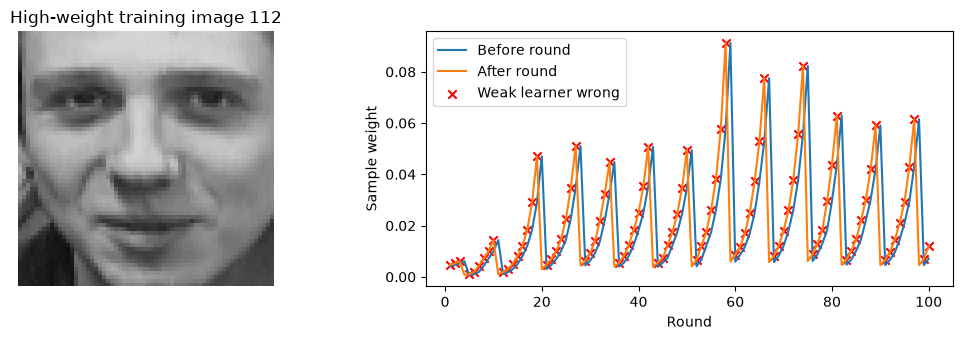

In [120]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 3.5)
)

axes[0].imshow(
    images[train_indices[face_idx]],
    cmap="gray",
    vmin=0,
    vmax=1
)

axes[0].set_title(
    f"High-weight training image {train_indices[face_idx]}"
)

axes[0].axis("off")


axes[1].plot(
    face_history["round"],
    face_history["weight_before"],
    label="Before round"
)

axes[1].plot(
    face_history["round"],
    face_history["weight_after"],
    label="After round"
)

wrong = face_history["weak_wrong"]

axes[1].scatter(
    face_history.loc[wrong, "round"],
    face_history.loc[wrong, "weight_after"],
    color="red",
    marker="x",
    label="Weak learner wrong"
)

axes[1].set(
    xlabel="Round",
    ylabel="Sample weight"
)

axes[1].legend()

plt.tight_layout()
(folder / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(folder / "figures" / "q2c_high_weight_image.png", dpi=160, bbox_inches="tight")
plt.show()

### Q2-D

In [121]:
boost_clean = samme_vectors(
    best_boosting, test_features
)

boost_masked = samme_vectors(
    best_boosting, masked_features
)

In [122]:
results = []

for name, clean, masked in [
    ("Single tree", tree_clean, tree_masked),
    ("Bagging", bag_clean, bag_masked),
    ("Boosting", boost_clean, boost_masked)
]:

    clean_accuracy = np.mean(
        labels_from_votes(clean) == test_labels
    )

    masked_accuracy = np.mean(
        labels_from_votes(masked) == test_labels
    )

    clean_confidence = clean.max(axis=1).mean()
    masked_confidence = masked.max(axis=1).mean()

    results.append({
        "model": name,
        "clean_accuracy": clean_accuracy,
        "masked_accuracy": masked_accuracy,
        "clean_confidence": clean_confidence,
        "masked_confidence": masked_confidence
    })

In [123]:
q2d = pd.DataFrame(results)

display(q2d.round(4))

,model,clean_accuracy,masked_accuracy,clean_confidence,masked_confidence
0,Single tree,0.6500,0.4125,0.9714,0.9929
1,Bagging,0.9000,0.5625,0.3775,0.2399
2,Boosting,0.4125,0.2875,0.1253,0.1245


In [124]:
bag_before = labels_from_votes(bag_clean)
bag_after = labels_from_votes(bag_masked)

boost_before = labels_from_votes(boost_clean)
boost_after = labels_from_votes(boost_masked)

In [125]:
different = np.flatnonzero(
    (bag_before != bag_after) !=
    (boost_before != boost_after)
)

In [126]:
response_difference = np.abs(
    (bag_masked - bag_clean) -
    (boost_masked - boost_clean)
).sum(axis=1)

In [127]:
i = None

if len(different) or response_difference.max() > 1e-12:

    if len(different):

        i = different[0]

        print(
            "Exactly one ensemble changes its predicted identity."
        )

    else:

        i = response_difference.argmax()

        print(
            "Both have the same label-change status; "
            "showing different vote-vector responses."
        )

    print(
        "Test image:", test_indices[i],
        "| True identity:", test_labels[i]
    )

else:

    print(
        "No differing ensemble response was found on these test images."
    )

Exactly one ensemble changes its predicted identity.
Test image: 1 | True identity: 0


In [128]:
if i is not None:

    pair = np.vstack([
        test_features[i],
        masked_features[i]
    ])

In [129]:
if i is not None:

    bag_pred = tree_predictions(
        final_bagging, pair
    )

    boost_pred = tree_predictions(
        best_boosting["trees"], pair
    )

    alphas = best_boosting["alphas"]

In [130]:
case_results = []

if i is not None:

    for name, pred, clean, masked, weights in [
        (
            "Bagging",
            bag_pred,
            bag_clean,
            bag_masked,
            np.ones(best_B)
        ),
        (
            "Boosting",
            boost_pred,
            boost_clean,
            boost_masked,
            alphas
        )
    ]:

        changed = pred[:, 0] != pred[:, 1]

        clean_disagreement = disagreement(
            vote_counts(pred[:, :1])
        )

        masked_disagreement = disagreement(
            vote_counts(pred[:, 1:])
        )

        changed_tree_fraction = changed.mean()

        changed_vote_weight = (
            weights[changed].sum() / weights.sum()
        )

        case_results.append({
            "model": name,
            "clean_prediction": labels_from_votes(clean[i:i+1])[0],
            "masked_prediction": labels_from_votes(masked[i:i+1])[0],
            "clean_confidence": clean[i].max(),
            "masked_confidence": masked[i].max(),
            "clean_disagreement": clean_disagreement,
            "masked_disagreement": masked_disagreement,
            "changed_tree_fraction": changed_tree_fraction,
            "changed_vote_weight": changed_vote_weight
        })

In [131]:
if case_results:

    case_table = pd.DataFrame(case_results)

    display(case_table.round(4))

,model,clean_prediction,masked_prediction,clean_confidence,masked_confidence,clean_disagreement,masked_disagreement,changed_tree_fraction,changed_vote_weight
0,Bagging,30,13,0.1700,0.1600,0.9459,0.9208,0.55,0.5500
1,Boosting,2,2,0.1278,0.1278,0.9453,0.9414,0.15,0.1542


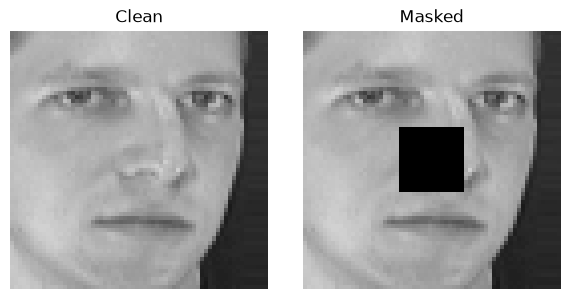

In [132]:
if i is not None:

    fig, axes = plt.subplots(
        1, 2,
        figsize=(6, 3)
    )

    for ax, image, title in zip(
        axes,
        [
            images[test_indices[i]],
            masked_images[i]
        ],
        ["Clean", "Masked"]
    ):

        ax.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    (folder / "figures").mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / "figures" / "q2d_clean_masked_face.png", dpi=160, bbox_inches="tight")
    plt.show()

In [133]:
if i is not None:

    changed_rounds = np.flatnonzero(
        boost_pred[:, 0] != boost_pred[:, 1]
    )

In [134]:
if i is not None:

    top = changed_rounds[
        np.argsort(-alphas[changed_rounds])[:3]
    ]

In [135]:
if i is not None and len(top):

    before = best_boosting["weights"][top]

In [136]:
if i is not None:

    if len(top):

        influential_trees = pd.DataFrame({
            "round": top + 1,
            "alpha": alphas[top],
            "clean_prediction": boost_pred[top, 0],
            "masked_prediction": boost_pred[top, 1],
            "max_training_weight": before.max(axis=1),
            "top10_training_weight": np.sort(
                before, axis=1
            )[:, -10:].sum(axis=1),
            "most_weighted_image": train_indices[
                before.argmax(axis=1)
            ]
        })

        display(influential_trees.round(6))

    else:

        print(
            "No selected boosting tree changes its prediction on this face."
        )

,round,alpha,clean_prediction,masked_prediction,max_training_weight,top10_training_weight,most_weighted_image
0,6,3.616020,5,0,0.009970,0.099704,81
1,12,3.340646,32,13,0.032650,0.184543,326
2,19,3.248335,5,13,0.031364,0.223101,326


# Q3

### Q3-A

In [137]:
R = 30

N = len(test_labels)
K = len(classes)

selected_tree_depth = tree_params["max_depth"]

In [138]:
if selected_tree_depth is None:

    depth_list = [2, 8, None]

    print(
        "Selected depth=None is already unlimited; "
        "no deeper setting exists."
    )

    print(
        "Comparing shallow=2, intermediate=8 "
        "and selected/unlimited=None."
    )

else:

    depth_list = [
        max(1, selected_tree_depth // 2),
        selected_tree_depth,
        None
    ]

depth_labels = [str(depth) for depth in depth_list]

print("Depths:", depth_list)

Selected depth=None is already unlimited; no deeper setting exists.
Comparing shallow=2, intermediate=8 and selected/unlimited=None.
Depths: [2, 8, None]


In [139]:
def leaf_stats(model, X):

    _, counts = np.unique(
        model.apply(X),
        return_counts=True
    )

    return {
        "leaves": len(counts),
        "mean_leaf_size": counts.mean(),
        "singleton_fraction": np.mean(counts == 1)
    }

In [140]:
def bias_variance(P):

    target = (
        test_labels[:, None] == classes[None, :]
    ).astype(float)

    mean_P = P.mean(axis=0)

    bias_squared = np.mean(
        np.sum((mean_P - target) ** 2, axis=1)
    )

    variance = np.mean(
        np.sum((P - mean_P) ** 2, axis=2)
    )

    accuracy = np.mean(
        classes[P.argmax(axis=2)] == test_labels[None, :],
        axis=1
    )

    return {
        "bias_squared": bias_squared,
        "variance": variance,
        "mean_test_accuracy": accuracy.mean(),
        "std_test_accuracy": accuracy.std(ddof=1)
    }

In [141]:
selected_vectors = {
    name: np.empty((R, N, K))
    for name in [
        "Single tree",
        "Bagging",
        "Boosting"
    ]
}

In [142]:
depth_vectors = {
    depth: {
        name: np.empty((R, N, K))
        for name in [
            "Single tree",
            "Bagging (100)"
        ]
    }
    for depth in depth_list
}

In [143]:
resamples = []

for r in range(R):

    rng = np.random.default_rng(
        get_seed(100, r)
    )

    idx = np.concatenate([
        rng.choice(
            np.flatnonzero(training_labels == label),
            size=6,
            replace=True
        )
        for label in classes
    ])

    resamples.append(idx)

resamples = np.array(resamples)

In [144]:
np.savez_compressed(
    folder / "split" / "q3_resamples.npz",
    positions=resamples,
    dataset_indices=train_indices[resamples]
)

In [145]:
print("Resample shape:", resamples.shape)
print("Repetitions:", R)
print("Samples per repetition:", resamples.shape[1])

Resample shape: (30, 240)
Repetitions: 30
Samples per repetition: 240


In [146]:
leaf_results = []

for r, idx in enumerate(resamples):

    print(f"\nRepetition {r + 1}/{R} :", flush=True)

    X_refit = training_features[idx]
    y_refit = training_labels[idx]

    for depth in depth_list:

        params = {
            **tree_params,
            "max_depth": depth
        }

        refit_tree = DecisionTreeClassifier(
            **params,
            random_state=get_seed(101, r)
        )

        refit_tree.fit(X_refit, y_refit)

        tree_vectors = refit_tree.predict_proba(
            test_features
        )

        B = (
            max(100, best_B)
            if depth == selected_tree_depth
            else 100
        )

        print(
            f"Repetition {r + 1}/{R} | Depth {depth} | Bagging {B} trees",
            flush=True
        )

        refit_trees, samples, _ = fit_bagging(
            X_refit,
            y_refit,
            params,
            B,
            get_seed(102, r)
        )

        pred = tree_predictions(
            refit_trees,
            test_features
        )

        votes_100 = vote_counts(pred[:100])

        depth_vectors[depth]["Single tree"][r] = (
            tree_vectors
        )

        depth_vectors[depth]["Bagging (100)"][r] = (
            votes_100 / 100
        )

        if depth == selected_tree_depth:

            selected_vectors["Single tree"][r] = (
                tree_vectors
            )

            selected_vectors["Bagging"][r] = (
                vote_counts(pred[:best_B]) / best_B
            )

        bag_stats = pd.DataFrame([
            leaf_stats(tree, X_refit[sample])
            for tree, sample in zip(
                refit_trees[:100],
                samples[:100]
            )
        ]).mean().to_dict()

        leaf_results.append({
            "repetition": r + 1,
            "depth": str(depth),
            "model": "Single tree",
            **leaf_stats(refit_tree, X_refit),
            "disagreement": np.nan
        })

        leaf_results.append({
            "repetition": r + 1,
            "depth": str(depth),
            "model": "Bagging (100)",
            **bag_stats,
            "disagreement": disagreement(votes_100)
        })

        print(
            f"Depth {depth} completed.",
            flush=True
        )

    print(
        f"Repetition {r + 1}/{R} | Training Boosting",
        flush=True
    )

    refit_boosting = fit_samme(
        X_refit,
        y_refit,
        best_depth,
        best_T,
        get_seed(103, r)
    )

    selected_vectors["Boosting"][r] = samme_vectors(
        refit_boosting,
        test_features
    )

    print(
        f"Repetition {r + 1}/{R} completed.\n",
        flush=True
    )


Repetition 1/30 :
Repetition 1/30 | Depth 2 | Bagging 100 trees
Trained 25/100 trees
Trained 50/100 trees
Trained 75/100 trees
Trained 100/100 trees
Depth 2 completed.
Repetition 1/30 | Depth 8 | Bagging 100 trees
Trained 25/100 trees
Trained 50/100 trees
Trained 75/100 trees
Trained 100/100 trees
Depth 8 completed.
Repetition 1/30 | Depth None | Bagging 100 trees
Trained 25/100 trees
Trained 50/100 trees
Trained 75/100 trees
Trained 100/100 trees
Depth None completed.
Repetition 1/30 | Training Boosting
Repetition 1/30 completed.


Repetition 2/30 :
Repetition 2/30 | Depth 2 | Bagging 100 trees
Trained 25/100 trees
Trained 50/100 trees
Trained 75/100 trees
Trained 100/100 trees
Depth 2 completed.
Repetition 2/30 | Depth 8 | Bagging 100 trees
Trained 25/100 trees
Trained 50/100 trees
Trained 75/100 trees
Trained 100/100 trees
Depth 8 completed.
Repetition 2/30 | Depth None | Bagging 100 trees
Trained 25/100 trees
Trained 50/100 trees
Trained 75/100 trees
Trained 100/100 trees
Depth No

In [147]:
q3a_results = []

for name, P in selected_vectors.items():

    statistics = bias_variance(P)

    q3a_results.append({
        "model": name,
        **statistics
    })

q3a = pd.DataFrame(q3a_results)

In [148]:
display(q3a.round(6))

,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,Single tree,0.420417,0.656250,0.461667,0.043043
1,Bagging,0.528493,0.024630,0.749583,0.044948
2,Boosting,0.887263,0.019304,0.325417,0.083012


### Q3-B

In [149]:
results = []

In [150]:
for depth in depth_list:

    for name, P in depth_vectors[depth].items():

        statistics = bias_variance(P)

        results.append({
            "depth": str(depth),
            "model": name,
            **statistics
        })

In [151]:
depth_results = pd.DataFrame(results)

display(depth_results.round(6))

,depth,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy
0,2,Single tree,0.913687,0.029679,0.061667,0.013508
1,2,Bagging (100),0.932887,0.011070,0.145000,0.051024
2,8,Single tree,0.785128,0.110036,0.158333,0.023519
3,8,Bagging (100),0.812435,0.018066,0.409583,0.066362
4,None,Single tree,0.420417,0.656250,0.461667,0.043043
5,None,Bagging (100),0.528493,0.024630,0.749583,0.044948


In [152]:
leaf_data = pd.DataFrame(leaf_results)

assert len(leaf_data) == R * len(depth_list) * 2
assert not leaf_data.duplicated(
    ["repetition", "depth", "model"]
).any()
assert leaf_data.groupby(["depth", "model"]).size().eq(R).all()

In [153]:
leaf_summary = (
    leaf_data
    .groupby(["depth", "model"], sort=False)[
        [
            "leaves",
            "mean_leaf_size",
            "singleton_fraction",
            "disagreement"
        ]
    ]
    .mean()
    .reset_index()
)

In [154]:
q3b = depth_results.merge(
    leaf_summary,
    on=["depth", "model"]
)

In [155]:
display(q3b.round(6))

,depth,model,bias_squared,variance,mean_test_accuracy,std_test_accuracy,leaves,mean_leaf_size,singleton_fraction,disagreement
0,2,Single tree,0.913687,0.029679,0.061667,0.013508,3.000000,80.000000,0.0,NaN
1,2,Bagging (100),0.932887,0.011070,0.145000,0.051024,3.156000,76.880000,0.0,0.961694
2,8,Single tree,0.785128,0.110036,0.158333,0.023519,9.166667,26.222222,0.0,NaN
3,8,Bagging (100),0.812435,0.018066,0.409583,0.066362,10.615667,22.901119,0.0,0.925167
4,None,Single tree,0.420417,0.656250,0.461667,0.043043,40.000000,6.000000,0.0,NaN
5,None,Bagging (100),0.528493,0.024630,0.749583,0.044948,39.339333,6.109582,0.0,0.829152


In [156]:
variance_table = q3b.pivot(
    index="depth",
    columns="model",
    values="variance"
)

variance_table = variance_table.reindex(
    depth_labels
)

In [157]:
variance_table["variance_removed"] = (
    variance_table["Single tree"]
    - variance_table["Bagging (100)"]
)

In [158]:
display(variance_table.round(6))

model,Bagging (100),Single tree,variance_removed
depth,,,
2,0.011070,0.029679,0.018609
8,0.018066,0.110036,0.091970
None,0.024630,0.656250,0.631620


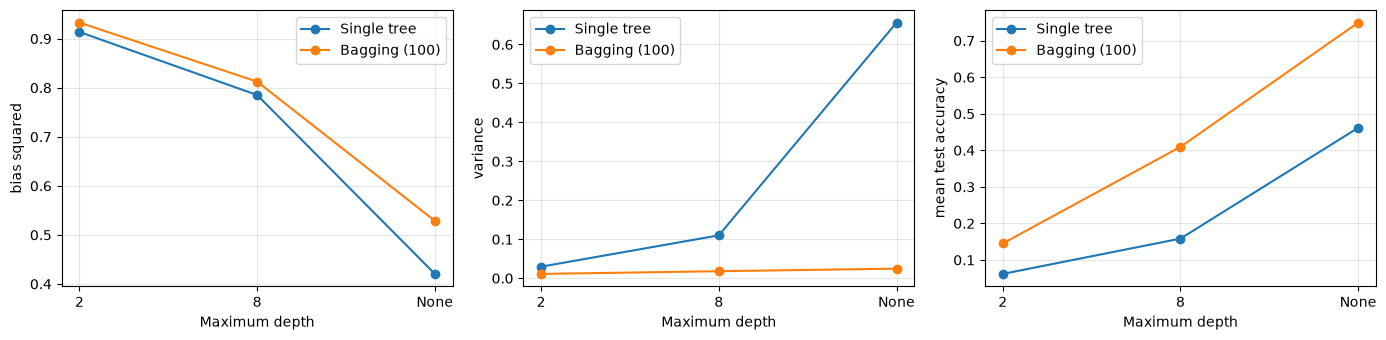

In [159]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(14, 3.5)
)

metrics = [
    "bias_squared",
    "variance",
    "mean_test_accuracy"
]

for ax, metric in zip(axes, metrics):

    for name in ["Single tree", "Bagging (100)"]:

        values = (
            q3b[q3b["model"] == name]
            .set_index("depth")
            .reindex(depth_labels)
        )

        ax.plot(
            depth_labels,
            values[metric],
            "o-",
            label=name
        )

    ax.set(
        xlabel="Maximum depth",
        ylabel=metric.replace("_", " ")
    )

    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

### Q3-C

In [160]:
single = (
    q3b[q3b["model"] == "Single tree"]
    .set_index("depth")
    .reindex(depth_labels)
)

In [161]:
bag = (
    q3b[q3b["model"] == "Bagging (100)"]
    .set_index("depth")
    .reindex(depth_labels)
)

In [162]:
accuracy_gain = 100 * (
    bag["mean_test_accuracy"] -
    single["mean_test_accuracy"]
)

In [163]:
bias_change = (
    bag["bias_squared"] -
    single["bias_squared"]
)

In [164]:
variance_removed = (
    single["variance"] -
    bag["variance"]
)

In [165]:
q3c = pd.DataFrame({
    "tree_accuracy": single["mean_test_accuracy"],
    "bagging_accuracy": bag["mean_test_accuracy"],
    "accuracy_gain_pp": accuracy_gain,
    "bias_change": bias_change,
    "variance_removed": variance_removed,
    "tree_mean_leaf_size": single["mean_leaf_size"],
    "bag_mean_leaf_size": bag["mean_leaf_size"],
    "bag_disagreement": bag["disagreement"]
})

In [166]:
display(q3c.round(6))

,tree_accuracy,bagging_accuracy,accuracy_gain_pp,bias_change,variance_removed,tree_mean_leaf_size,bag_mean_leaf_size,bag_disagreement
depth,,,,,,,,
2,0.061667,0.145000,8.333333,0.019200,0.018609,80.000000,76.880000,0.961694
8,0.158333,0.409583,25.125000,0.027307,0.091970,26.222222,22.901119,0.925167
None,0.461667,0.749583,28.791667,0.108076,0.631620,6.000000,6.109582,0.829152


In [167]:
largest_gain = q3c["accuracy_gain_pp"].max()

In [168]:
winners = q3c.index[
    np.isclose(q3c["accuracy_gain_pp"], largest_gain)
].tolist()

In [169]:
deepest = depth_labels[-1]

In [170]:

print(
    f"Largest observed gain: {largest_gain:.2f} percentage points" )
print(
    f"Deepest depth: {deepest}"
)   


Largest observed gain: 28.79 percentage points
Deepest depth: None


In [171]:
if largest_gain <= 0:

    print(
        "None of these depths shows a positive mean accuracy gain."
    )

In [172]:
if deepest in winners:

    print(
        "The deepest setting is among the best here and "
        "this does not establish that it always must be."
    )

else:

    print(
        "The deepest setting does not give the largest "
        "accuracy gain in these experiments."
    )

The deepest setting is among the best here and this does not establish that it always must be.


In [173]:
for depth in depth_labels:

    tree = single.loc[depth]
    bagging = bag.loc[depth]

    print("Depth:", depth)

    print("Bias squared - Tree:", round(tree["bias_squared"], 4),
          "Bagging:", round(bagging["bias_squared"], 4))

    print("Variance - Tree:", round(tree["variance"], 4),
          "Bagging:", round(bagging["variance"], 4))

    print("Mean leaf size - Tree:", round(tree["mean_leaf_size"], 2),
          "Bagging:", round(bagging["mean_leaf_size"], 2))

    print("Bagging disagreement:", round(bagging["disagreement"], 4))

    print("Accuracy gain:", round(q3c.loc[depth, "accuracy_gain_pp"], 2), "pp")

    print()

Depth: 2
Bias squared - Tree: 0.9137 Bagging: 0.9329
Variance - Tree: 0.0297 Bagging: 0.0111
Mean leaf size - Tree: 80.0 Bagging: 76.88
Bagging disagreement: 0.9617
Accuracy gain: 8.33 pp

Depth: 8
Bias squared - Tree: 0.7851 Bagging: 0.8124
Variance - Tree: 0.11 Bagging: 0.0181
Mean leaf size - Tree: 26.22 Bagging: 22.9
Bagging disagreement: 0.9252
Accuracy gain: 25.12 pp

Depth: None
Bias squared - Tree: 0.4204 Bagging: 0.5285
Variance - Tree: 0.6562 Bagging: 0.0246
Mean leaf size - Tree: 6.0 Bagging: 6.11
Bagging disagreement: 0.8292
Accuracy gain: 28.79 pp



### Q3-D

In [174]:
accuracy_results = q2d[
    ["model", "clean_accuracy", "masked_accuracy"]
]

In [175]:
variance_results = q3a[
    ["model", "bias_squared", "variance"]
]

In [176]:
q3d = accuracy_results.merge(
    variance_results,
    on="model"
)

In [177]:
q3d["accuracy_drop_pp"] = 100 * (
    q3d["clean_accuracy"] - q3d["masked_accuracy"]
)

In [178]:
display(q3d.round(6))

,model,clean_accuracy,masked_accuracy,bias_squared,variance,accuracy_drop_pp
0,Single tree,0.6500,0.4125,0.420417,0.656250,23.75
1,Bagging,0.9000,0.5625,0.528493,0.024630,33.75
2,Boosting,0.4125,0.2875,0.887263,0.019304,12.50


In [179]:
minimum_variance = q3d["variance"].min()

stable = q3d.loc[
    np.isclose(q3d["variance"], minimum_variance),
    "model"
].tolist()

print("Lowest class-vector variance across refits:", stable)

Lowest class-vector variance across refits: ['Boosting']


In [180]:
largest_drop = q3d["accuracy_drop_pp"].max()

sensitive = q3d.loc[
    np.isclose(q3d["accuracy_drop_pp"], largest_drop),
    "model"
].tolist()

print("Largest absolute masking accuracy drop:", sensitive)
print("Accuracy drop:", round(largest_drop, 2), "percentage points")

Largest absolute masking accuracy drop: ['Bagging']
Accuracy drop: 33.75 percentage points


In [181]:
highest_accuracy = q3d["clean_accuracy"].max()

best_accuracy = q3d.loc[
    np.isclose(q3d["clean_accuracy"], highest_accuracy),
    "model"
].tolist()

print("Highest clean test accuracy:", best_accuracy)

Highest clean test accuracy: ['Bagging']


In [182]:
if set(stable) & set(best_accuracy):

    print(
        "At least one lowest-variance model also has the best accuracy in this experiment."
    )

else:

    print(
        "The lowest-variance model does not have the best clean test accuracy."
    )

The lowest-variance model does not have the best clean test accuracy.


## Save Results

In [183]:
logs_dir = folder / "logs"
logs_dir.mkdir(parents=True, exist_ok=True)

best_boosting["history"].to_csv(
    logs_dir / "boosting_history.csv", index=False
)
face_history.to_csv(
    logs_dir / "face_history.csv", index=False
)
leaf_data.to_csv(
    logs_dir / "q3_leaf_statistics.csv", index=False
)

tables = {
    "q1a": q1a.drop(columns="depth_order"),
    "q1b": q1b, "q1c": q1c, "q1d": q1d,
    "q2b": q2b, "q2c": q2c, "q2d": q2d,
    "q3a": q3a, "q3b": q3b, "q3c": q3c, "q3d": q3d
}

for name, table in tables.items():
    table.to_csv(logs_dir / f"{name}.csv", index=True)

In [184]:
import json

settings = {
    "seed": seed,
    "tree_parameters": tree_params,
    "bagging_trees": best_B,
    "boosting_depth": best_depth,
    "boosting_requested_rounds": best_T,
    "boosting_actual_rounds": used_T,
    "q3_repetitions": R,
    "q3_depths": depth_list,
    "mask_rows": [row_start, row_end],
    "mask_columns": [column_start, column_end],
    "mask_value": 0
}

(folder / "configuration.json").write_text(
    json.dumps(settings, indent=2),
    encoding="utf-8"
)

403

In [ ]:
import sklearn
import matplotlib

packages = [
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    "ipython",
    "ipykernel"
]

(folder / "requirements.txt").write_text(
    "\n".join(packages) + "\n",
    encoding="utf-8"
)

84